# Explore the asl-signs data

Before building a model, look at the data and find out what the preprocessing has to deal with:

1. **See a sign move:** load a few clips with pandas and plot the hand points frame by frame.
2. **Check 1:** how many frames clips have.
3. **Check 2:** how often a hand is missing.
4. **Check 3:** how many clips each sign has.

Paths are relative to `ml/`, which is where VS Code runs notebooks in this repo (see `.vscode/settings.json`).

In [ ]:
import io
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

archive = zipfile.ZipFile("data/asl-signs/asl-signs.zip")

## The clip list

`train.csv` has one row per clip: where its file is, who signed it, and which sign it is.

In [ ]:
train = pd.read_csv(archive.open("train.csv"))
print(train.shape)
train.head()

(94477, 4)


,path,participant_id,sequence_id,sign
0,train_landmark_files/26734/1000035562.parquet,26734,1000035562,blow
1,train_landmark_files/28656/1000106739.parquet,28656,1000106739,wait
2,train_landmark_files/16069/100015657.parquet,16069,100015657,cloud
3,train_landmark_files/25571/1000210073.parquet,25571,1000210073,bird
4,train_landmark_files/62590/1000240708.parquet,62590,1000240708,owie


## Load one clip

Each clip is a parquet file with **one row per landmark per frame**. We read it straight out of the zip (the zip is never unzipped; see CLAUDE.md).

In [ ]:
def load_clip(path):
    """Read one clip's parquet file from the zip into a DataFrame."""
    return pd.read_parquet(io.BytesIO(archive.read(path)))


hello = train[train["sequence_id"] == 1474345895].iloc[0]
clip = load_clip(hello["path"])
clip.head()

,frame,row_id,type,landmark_index,x,y,z
0,22,22-face-0,face,0,0.608742,0.363407,-0.037085
1,22,22-face-1,face,1,0.603862,0.333284,-0.066214
2,22,22-face-2,face,2,0.605291,0.344775,-0.036898
3,22,22-face-3,face,3,0.584911,0.303069,-0.048766
4,22,22-face-4,face,4,0.601346,0.322587,-0.069864


Every frame has 543 rows: 468 face points, 33 body (pose) points and 21 points per hand. `groupby` counts the rows of each type, and dividing by the number of frames gives the landmarks per frame:

In [ ]:
n_frames = clip["frame"].nunique()
print(f"{len(clip):,} rows / {n_frames} frames = {len(clip) // n_frames} rows per frame")
clip.groupby("type")["landmark_index"].count() // n_frames

15,204 rows / 28 frames = 543 rows per frame


type
face          468
left_hand      21
pose           33
right_hand     21
Name: landmark_index, dtype: int64

## See a sign move

Each hand is 21 points: the wrist (0) and four points up each finger. `HAND_CONNECTIONS` lists which points to join with a line so the hand looks like a hand.

`x` and `y` are fractions of the camera image's width and height, and `y` grows **downwards** (as in images), so the y-axis is flipped to show the hand the right way up. All frames share the same axes, so the movement between frames is real movement.

In [ ]:
HAND_CONNECTIONS = [
    (0, 1), (1, 2), (2, 3), (3, 4),  # thumb
    (0, 5), (5, 6), (6, 7), (7, 8),  # index finger
    (9, 10), (10, 11), (11, 12),  # middle finger
    (13, 14), (14, 15), (15, 16),  # ring finger
    (0, 17), (17, 18), (18, 19), (19, 20),  # little finger
    (5, 9), (9, 13), (13, 17),  # palm
]
HAND_COLOURS = {"left_hand": "tab:blue", "right_hand": "tab:orange"}


def plot_hands(clip, title, n_frames=12):
    """Draw both hands in n_frames evenly spaced frames of a clip, one small plot per frame."""
    hands = clip[clip["type"].isin(HAND_COLOURS.keys())]
    all_frames = hands["frame"].unique()
    frames = all_frames[np.linspace(0, len(all_frames) - 1, n_frames).astype(int)]

    fig, axes = plt.subplots(1, n_frames, figsize=(2 * n_frames, 2.6))
    for ax, frame in zip(axes, frames):
        for hand_type, colour in HAND_COLOURS.items():
            points = hands[(hands["frame"] == frame) & (hands["type"] == hand_type)].set_index("landmark_index")
            if points["x"].isna().all():  # this hand wasn't detected in this frame
                continue
            for a, b in HAND_CONNECTIONS:
                ax.plot(points.loc[[a, b], "x"], points.loc[[a, b], "y"], color=colour, linewidth=1)
            ax.scatter(points["x"], points["y"], color=colour, s=4)
        ax.set_title(f"frame {frame}", fontsize=8)
        ax.set_xlim(hands["x"].min() - 0.02, hands["x"].max() + 0.02)
        ax.set_ylim(hands["y"].max() + 0.02, hands["y"].min() - 0.02)  # flipped: y grows downwards
        ax.set_aspect("equal")
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(f"{title}  (blue = left hand, orange = right hand)")
    plt.show()

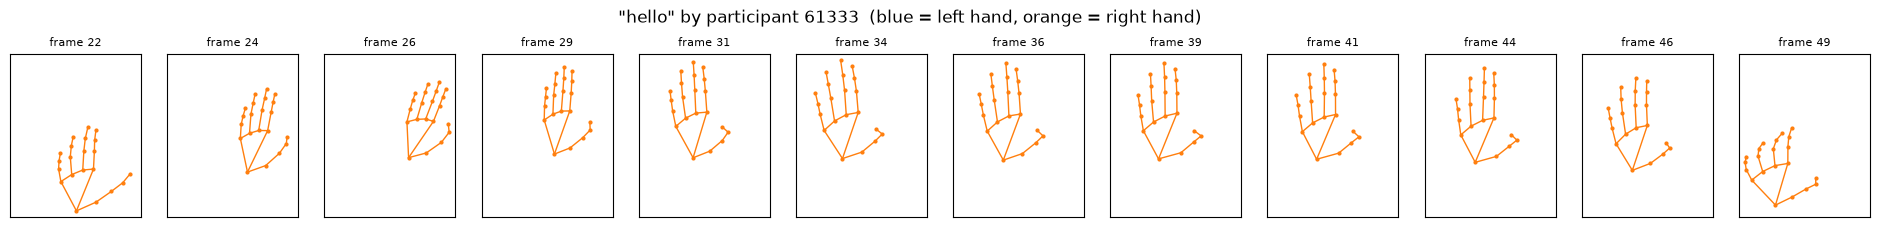

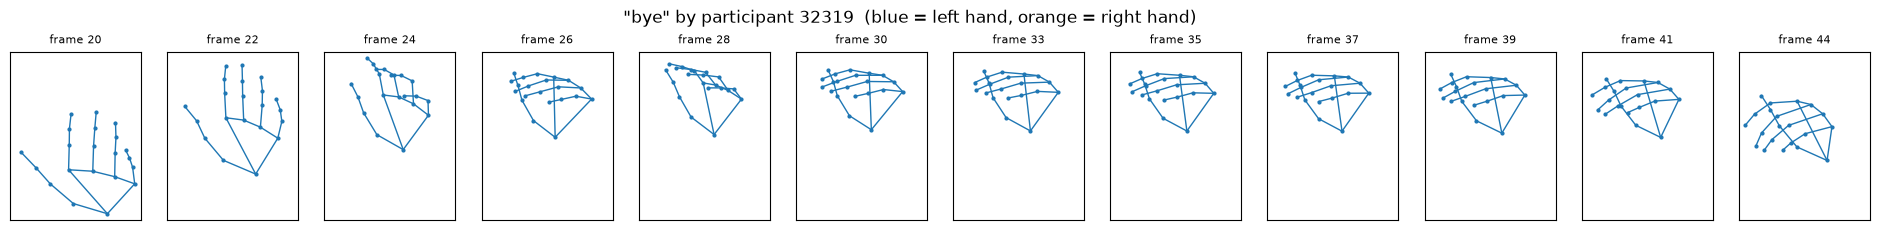

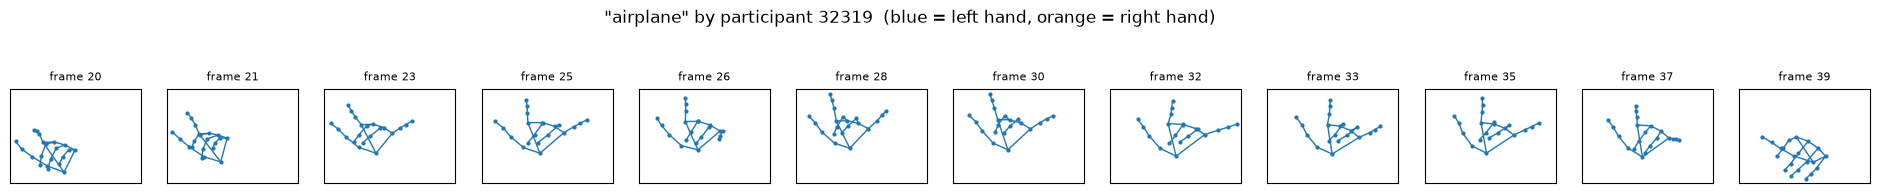

In [ ]:
for sequence_id in [1474345895, 1095133532, 1037905016]:
    row = train[train["sequence_id"] == sequence_id].iloc[0]
    plot_hands(load_clip(row["path"]), f'"{row["sign"]}" by participant {row["participant_id"]}')

Try other clips: pick any `sequence_id` from `train`, e.g. `train[train["sign"] == "dog"].head()`.

From here on, the checks cover **all 94k clips**. Opening 94k parquet files each time would be slow, so we use the files `scripts/extract_landmarks.py` already made: `clips.csv` (one row per clip, including its frame count) and `landmarks.npy` (every frame, 94 landmarks each).

In [ ]:
clips = pd.read_csv("data/processed/clips.csv")
landmarks = np.load("data/processed/landmarks.npy", mmap_mode="r")  # mmap: read from disk only when needed
clips.head()

,sequence_id,participant_id,sign,label,start,length
0,1000035562,26734,blow,25,0,23
1,1000106739,28656,wait,232,23,11
2,100015657,16069,cloud,48,34,105
3,1000210073,25571,bird,23,139,12
4,1000240708,62590,owie,164,151,18


## Check 1: how many frames clips have

In [ ]:
clips["length"].describe()

count    94477.000000
mean        37.935021
std         44.177069
min          2.000000
25%         12.000000
50%         22.000000
75%         44.000000
max        537.000000
Name: length, dtype: float64

In [ ]:
clips["length"].quantile([0.5, 0.75, 0.9, 0.95, 0.99])

0.50     22.0
0.75     44.0
0.90     92.0
0.95    135.0
0.99    219.0
Name: length, dtype: float64

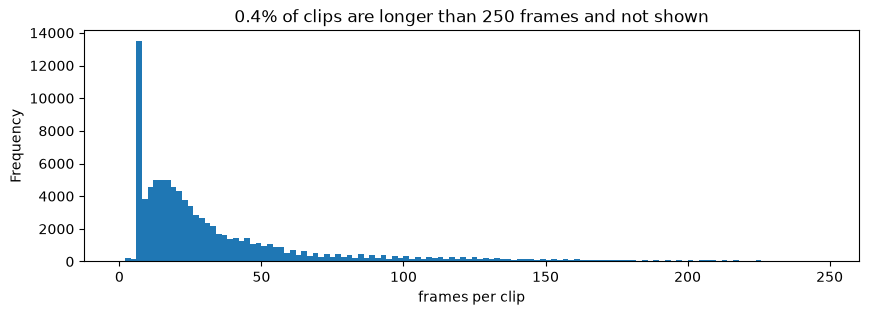

In [ ]:
fig, ax = plt.subplots(figsize=(10, 3))
clips["length"].plot.hist(bins=range(0, 250, 2), ax=ax)
ax.set_xlabel("frames per clip")
ax.set_title(f"{(clips['length'] >= 250).mean():.1%} of clips are longer than 250 frames and not shown")
plt.show()

Some signs are naturally longer than others. `groupby` gives the median length per sign:

In [ ]:
length_per_sign = clips.groupby("sign")["length"].median().sort_values()
print("Shortest signs:", length_per_sign.head(5).to_dict())
print("Longest signs: ", length_per_sign.tail(5).to_dict())

Shortest signs: {'down': 12.0, 'drop': 12.5, 'quiet': 12.5, 'wet': 13.0, 'beside': 13.0}
Longest signs:  {'backyard': 30.5, 'nap': 31.0, 'puppy': 31.0, 'refrigerator': 33.0, 'mitten': 36.0}


## Check 2: how often a hand is missing

A hand is either fully detected in a frame or completely missing (all 21 points NaN), so checking the wrist is enough. In the clip we loaded earlier, `pivot` turns the wrist rows into a table with one row per frame and one column per hand:

In [ ]:
wrists = clip[clip["type"].str.endswith("hand") & (clip["landmark_index"] == 0)]
wrist_x = wrists.pivot(index="frame", columns="type", values="x")
print("Share of frames each hand is missing:", wrist_x.isna().mean().round(2).to_dict())
wrist_x.head()

Share of frames each hand is missing: {'left_hand': 1.0, 'right_hand': 0.0}


type,left_hand,right_hand
frame,,
22,NaN,0.278391
23,NaN,0.301212
24,NaN,0.323816
25,NaN,0.335069
26,NaN,0.336651


Now the whole dataset. In `landmarks.npy`, the left wrist is landmark 40 and the right wrist is landmark 73. We build a DataFrame with one row per frame, then `groupby` clip and participant.

In [ ]:
frames = pd.DataFrame({
    "sequence_id": np.repeat(clips["sequence_id"].to_numpy(), clips["length"].to_numpy()),
    "participant_id": np.repeat(clips["participant_id"].to_numpy(), clips["length"].to_numpy()),
    "left_hand": ~np.isnan(landmarks[:, 40, 0]),
    "right_hand": ~np.isnan(landmarks[:, 73, 0]),
})
frames["any_hand"] = frames["left_hand"] | frames["right_hand"]

print(f"Frames: {len(frames):,}")
print("Share of frames where each hand is detected:")
frames[["left_hand", "right_hand", "any_hand"]].mean().round(2)

Frames: 3,583,987
Share of frames where each hand is detected:


left_hand     0.30
right_hand    0.31
any_hand      0.61
dtype: float64

In [ ]:
hand_per_clip = frames.groupby("sequence_id")["any_hand"].mean()
print(f"Clips with no hand in any frame: {(hand_per_clip == 0).sum():,} ({(hand_per_clip == 0).mean():.1%})")
print(f"Clips with a hand in every frame: {(hand_per_clip == 1).sum():,} ({(hand_per_clip == 1).mean():.1%})")

Clips with no hand in any frame: 0 (0.0%)
Clips with a hand in every frame: 18,423 (19.5%)


Most signs are made with one hand, the **dominant** one, and that depends on the signer. Grouping by participant shows it:

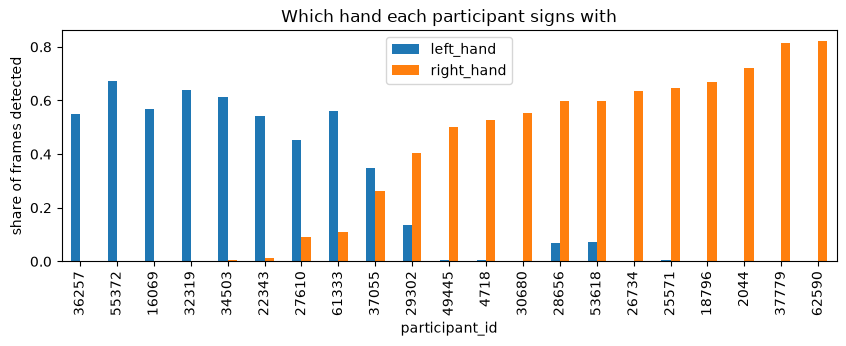

In [ ]:
by_participant = frames.groupby("participant_id")[["left_hand", "right_hand"]].mean()
ax = by_participant.sort_values("right_hand").plot.bar(figsize=(10, 3), color=["tab:blue", "tab:orange"])
ax.set_ylabel("share of frames detected")
ax.set_title("Which hand each participant signs with")
plt.show()

## Check 3: how many clips each sign has

In [ ]:
clips_per_sign = clips["sign"].value_counts()
clips_per_sign.describe()

count    250.000000
mean     377.908000
std       19.395367
min      299.000000
25%      369.000000
50%      381.500000
75%      391.000000
max      415.000000
Name: count, dtype: float64

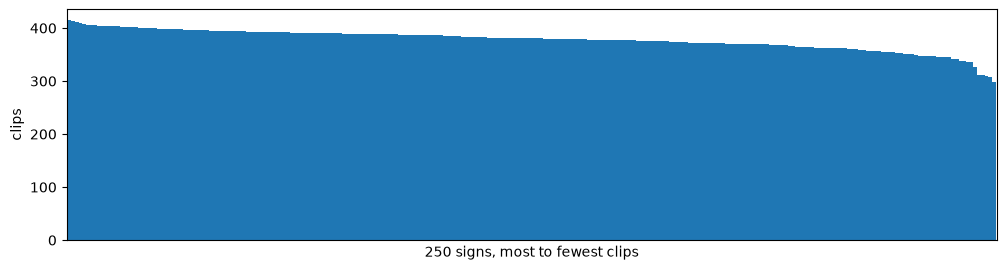

Most clips:  {'listen': 415, 'look': 414, 'shhh': 411}
Fewest clips: {'beside': 310, 'vacuum': 307, 'zipper': 299}


In [ ]:
fig, ax = plt.subplots(figsize=(12, 3))
clips_per_sign.plot.bar(ax=ax, width=1)
ax.set_xticks([])
ax.set_xlabel("250 signs, most to fewest clips")
ax.set_ylabel("clips")
plt.show()
print("Most clips: ", clips_per_sign.head(3).to_dict())
print("Fewest clips:", clips_per_sign.tail(3).to_dict())

Clips per participant matters too: validation is split by participant, so each participant is a chunk of data that moves as a whole.

In [ ]:
clips["participant_id"].value_counts().describe()

count      21.000000
mean     4498.904762
std       502.892822
min      3338.000000
25%      4545.000000
50%      4677.000000
75%      4826.000000
max      4968.000000
Name: count, dtype: float64

## What the preprocessing has to deal with

1. **Clip length varies a lot:** 2 to 537 frames, median 22, and 95% of clips are 135 frames or fewer. A model needs a fixed-size input, so clips must be padded, trimmed or resampled to one length.
   - 11,744 clips (12%) are **exactly 6 frames**. That many identical lengths looks like a recording artefact rather than real signing. Look at some of them before deciding whether to keep them.
2. **Hands are often missing:** 39% of frames have no hand at all, and only about 1 in 5 clips has a hand in every frame. Every clip has at least one frame with a hand. Frames without a hand carry no sign information and can be dropped; any remaining NaN must be replaced (e.g. with 0) before training, because a single NaN makes the model's output NaN.
3. **Signers use different hands:** about 8 of the 21 participants sign with the left hand and most of the rest with the right. Mirroring left-handed clips (flip `x`, swap the two hands) would let the model see one dominant hand instead of having to learn every sign twice.
4. **Signs are balanced:** 299 to 415 clips per sign, so no sign needs extra weight in training.
5. **Participants are big chunks of data:** 3,338 to 4,968 clips each. Holding out 3 or 4 participants for validation gives a test on unseen signers of about 15–20% of the data.